# ResNet-50: transfer learning на ImageNet

450 изображений, девять классов объединены в три метакласса:

- Фрукты: banana, orange, pineapple.
- Обувь: running shoe, sandal, cowboy boot.
- Бытовая техника: microwave, refrigerator, washer.

Сравниваем замороженный backbone, частичный и полный fine-tuning, линейную и MLP-головы. Восемь конфигураций на четырёх разбиениях, всего 32 обучения.

Совместная лабораторная работа с Кириллом Слепцовым.

[Результаты и запуск](../docs/computer-vision.md) · [Источники](../PROVENANCE.md)

In [1]:
import torch
print("torch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "НЕТ (включите GPU в Runtime)")

torch: 2.11.0+cu130
GPU: Tesla T4


In [2]:
import os
try:
    import google.colab
    ON_COLAB = True
except ImportError:
    ON_COLAB = False
ON_KAGGLE = os.path.exists('/kaggle/input') and not ON_COLAB
print("Colab:", ON_COLAB, "| Kaggle:", ON_KAGGLE)


## 1. Классы ImageNet

Названия и индексы 1000 классов ImageNet-1k берём из метаданных весов torchvision.

In [3]:
from torchvision import models

CATS = models.ResNet50_Weights.IMAGENET1K_V2.meta["categories"]
print("всего классов:", len(CATS))
print("первые:", CATS[:5])
print("последние:", CATS[-3:])


def find(*words):
    # поиск классов по подстроке в названии
    for i, c in enumerate(CATS):
        if any(w in c.lower() for w in words):
            print(f"   {i:4d}  {c}")


print("\nФрукты и овощи (поиск по ключевым словам):")
find("banana", "orange", "pineapple", "lemon", "strawberry", "pomegranate", "fig", "jackfruit", "apple")
print("\nОбувь:")
find("shoe", "boot", "sandal", "clog", "loafer")
print("\nБытовая техника:")
find("microwave", "refrigerator", "washer", "dishwasher", "stove", "toaster", "oven", "vacuum")

всего классов: 1000
первые: ['tench', 'goldfish', 'great white shark', 'tiger shark', 'hammerhead']
последние: ['bolete', 'ear', 'toilet tissue']

Фрукты и овощи (поиск по ключевым словам):
    949  strawberry
    950  orange
    951  lemon
    952  fig
    953  pineapple
    954  banana
    955  jackfruit
    956  custard apple
    957  pomegranate

Обувь:
    502  clog
    514  cowboy boot
    630  Loafer
    770  running shoe
    774  sandal
    788  shoe shop

Бытовая техника:
    534  dishwasher
    544  Dutch oven
    651  microwave
    760  refrigerator
    827  stove
    859  toaster
    882  vacuum
    897  washer


In [4]:
# Соседние индексы показывают, что похожие по смыслу классы в ImageNet часто идут рядом (например, плоды)
print("Классы 945-960:")
for i in range(945, 960):
    print(f"   {i}  {CATS[i]}")

Классы 945-960:
   945  bell pepper
   946  cardoon
   947  mushroom
   948  Granny Smith
   949  strawberry
   950  orange
   951  lemon
   952  fig
   953  pineapple
   954  banana
   955  jackfruit
   956  custard apple
   957  pomegranate
   958  hay
   959  carbonara


In [5]:
# Выбранные классы: проверяем, что индексы соответствуют ожидаемым названиям
CHOSEN = {"banana": 954, "orange": 950, "pineapple": 953,
          "running shoe": 770, "sandal": 774, "cowboy boot": 514,
          "microwave": 651, "refrigerator": 760, "washer": 897}
for name, idx in CHOSEN.items():
    print(f"{name:14s} idx={idx:4d} -> в списке ImageNet: {CATS[idx]}")

banana         idx= 954 -> в списке ImageNet: banana
orange         idx= 950 -> в списке ImageNet: orange
pineapple      idx= 953 -> в списке ImageNet: pineapple
running shoe   idx= 770 -> в списке ImageNet: running shoe
sandal         idx= 774 -> в списке ImageNet: sandal
cowboy boot    idx= 514 -> в списке ImageNet: cowboy boot
microwave      idx= 651 -> в списке ImageNet: microwave
refrigerator   idx= 760 -> в списке ImageNet: refrigerator
washer         idx= 897 -> в списке ImageNet: washer


### Метаклассы

В каждой группе по три исходных класса. Все они входят в ImageNet-1k, на котором предобучен backbone. Эксперимент проверяет перенос признаков на объединённые классы внутри того же домена.

## 2. Подвыборка ImageNet

In [6]:
EPOCHS = 8
BS = 64
SEED = 42

REPO_DIR = os.getcwd()
if os.path.basename(REPO_DIR) == "notebooks":
    REPO_DIR = os.path.dirname(REPO_DIR)

if ON_KAGGLE:
    OUT_DIR = os.environ.get("RESNET50_OUT_DIR", "/kaggle/working/resnet50-runs")
    WORKERS = 4
elif ON_COLAB:
    LOCAL_DATA_DIR = os.environ.get("IMAGENET9_DIR", "/content/imagenet9")
    OUT_DIR = os.environ.get("RESNET50_OUT_DIR", "/content/resnet50-runs")
    WORKERS = 2
else:
    LOCAL_DATA_DIR = os.environ.get("IMAGENET9_DIR", os.path.join(REPO_DIR, "data", "imagenet9"))
    OUT_DIR = os.environ.get("RESNET50_OUT_DIR", os.path.join(REPO_DIR, "runs", "resnet50"))
    # Классы Dataset определены в ноутбуке; 0 избегает spawn-проблем локальных ядер.
    WORKERS = 0


### Загрузка девяти классов

Если локальных данных нет, следующая ячейка предложит авторизацию Hugging Face и загрузит выбранные классы. Сначала получите доступ к ImageNet и примите условия набора.

Используется `SPLIT = "validation"`, по 50 изображений на класс, всего 450. Из них формируются собственные train/val/test. В Colab сохраните файлы из `/content` до завершения сессии.

In [7]:
import os

SPLIT = "validation"
MAX_PER_CLASS = 50 if SPLIT == "validation" else 1300

NEED = ["n07753592", "n07747607", "n07753275", "n04120489", "n04133789",
        "n03124043", "n03761084", "n04070727", "n04554684"]

if not ON_KAGGLE and not os.path.isdir(LOCAL_DATA_DIR):
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "datasets", "huggingface_hub"], check=True)
    from huggingface_hub import login
    from datasets import load_dataset
    from collections import Counter

    login()

    # индекс класса ImageNet-1k -> wnid
    IDX2WNID = {954: "n07753592", 950: "n07747607", 953: "n07753275",
                770: "n04120489", 774: "n04133789", 514: "n03124043",
                651: "n03761084", 760: "n04070727", 897: "n04554684"}

    ds = load_dataset("ILSVRC/imagenet-1k", split=SPLIT, streaming=True)
    counts = Counter()
    for k, ex in enumerate(ds):
        wnid = IDX2WNID.get(ex["label"])
        if wnid is not None and counts[wnid] < MAX_PER_CLASS:
            d = f"{LOCAL_DATA_DIR}/{wnid}"
            os.makedirs(d, exist_ok=True)
            ex["image"].convert("RGB").save(f"{d}/{counts[wnid]:05d}.jpg", quality=95)
            counts[wnid] += 1
            if all(counts[w] >= MAX_PER_CLASS for w in NEED):
                break
        if k % 20000 == 0:
            print(f"просмотрено {k}, сохранено {sum(counts.values())}")
    print(dict(counts))


просмотрено 0, сохранено 0
просмотрено 20000, сохранено 184
просмотрено 40000, сохранено 358
{'n07753592': 50, 'n04133789': 50, 'n04554684': 50, 'n03124043': 50, 'n04120489': 50, 'n07747607': 50, 'n07753275': 50, 'n03761084': 50, 'n04070727': 50}


In [8]:
os.makedirs(OUT_DIR, exist_ok=True)

if ON_KAGGLE:
    def find_train_dir(root='/kaggle/input', target='n07753592', max_depth=7):
        # ищем папку train, где лежат папки-wnid (внутрь самих wnid-папок не заходим)
        for cur, dirs, _ in os.walk(root):
            if target in dirs:
                return cur
            dirs[:] = [d for d in dirs if not (len(d) == 9 and d[0] == 'n' and d[1:].isdigit())]
            if cur[len(root):].count(os.sep) >= max_depth:
                dirs[:] = []
        return None

    LOCAL_DATA_DIR = find_train_dir()
    assert LOCAL_DATA_DIR, "Не нашёл папку train с ImageNet: проверьте, что соревнование добавлено в Input"

print("данные:", LOCAL_DATA_DIR)
needed = ["n07753592", "n07747607", "n07753275", "n04120489", "n04133789",
          "n03124043", "n03761084", "n04070727", "n04554684"]
missing = [w for w in needed if not os.path.isdir(os.path.join(LOCAL_DATA_DIR, w))]
print("не хватает папок:", missing if missing else "всё на месте")

данные: /content/imagenet9
не хватает папок: всё на месте


## 3. Датасет и разбиение

Train/val/test: **70/15/15**, стратификация по девяти исходным классам. Train используется для обучения весов, validation для выбора checkpoint и конфигурации. Test-метрики рассчитываются для каждой конфигурации и показаны в сводках.

Предобработка: `Resize(256) → CenterCrop(224)`, нормализация ImageNet. На train добавлены `RandomResizedCrop`, горизонтальный flip и `ColorJitter`.

In [9]:
import json, random
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, classification_report
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

META = {
    "fruits":     {"banana": "n07753592", "orange": "n07747607", "pineapple": "n07753275"},
    "footwear":   {"running shoe": "n04120489", "sandal": "n04133789", "cowboy boot": "n03124043"},
    "appliances": {"microwave": "n03761084", "refrigerator": "n04070727", "washer": "n04554684"},
}
META_NAMES = list(META)
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]


def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


def collect_samples(root):
    samples = []
    for mi, (mname, classes) in enumerate(META.items()):
        for cname, wnid in classes.items():
            d = Path(root) / wnid
            if not d.is_dir():
                raise FileNotFoundError(f"Нет папки {d} (класс '{cname}')")
            for p in sorted(d.iterdir()):
                if p.suffix.lower() in {".jpeg", ".jpg", ".png"}:
                    samples.append((str(p), mi, wnid))
    return samples


class MetaDS(Dataset):
    def __init__(self, items, tf):
        self.items, self.tf = items, tf
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        p, y, _ = self.items[i]
        return self.tf(Image.open(p).convert("RGB")), y


def make_loaders(root, bs, workers, seed):
    samples = collect_samples(root)
    strat = [s[2] for s in samples]
    trainval, test = train_test_split(samples, test_size=0.15, stratify=strat, random_state=seed)
    train, val = train_test_split(trainval, test_size=0.1765,
                                  stratify=[s[2] for s in trainval], random_state=seed)   # итого 70/15/15

    train_tf = transforms.Compose([
        transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.ColorJitter(0.2, 0.2, 0.2),
        transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
    eval_tf = transforms.Compose([
        transforms.Resize(256), transforms.CenterCrop(224),
        transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

    mk = lambda ds, sh: DataLoader(ds, batch_size=bs, shuffle=sh, num_workers=workers, pin_memory=True)
    print(f"train={len(train)} val={len(val)} test={len(test)}")
    return (mk(MetaDS(train, train_tf), True), mk(MetaDS(val, eval_tf), False),
            mk(MetaDS(test, eval_tf), False)), (train, val, test)

In [10]:
seed_all(SEED)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
loaders, splits = make_loaders(LOCAL_DATA_DIR, BS, WORKERS, SEED)

from collections import Counter
for nm, part in zip(["train", "val", "test"], splits):
    c = Counter(META_NAMES[s[1]] for s in part)
    print(nm, dict(c))

train=314 val=68 test=68
train {'appliances': 105, 'fruits': 104, 'footwear': 105}
val {'fruits': 23, 'appliances': 23, 'footwear': 22}
test {'appliances': 22, 'footwear': 23, 'fruits': 23}


In [11]:
# Визуальная проверка: по 4 случайных картинки каждого из 9 классов (строки сгруппированы по метаклассам)
import matplotlib.pyplot as plt

wnid2name = {w: c for cls in META.values() for c, w in cls.items()}
train_items = splits[0]
rng = random.Random(0)
fig, axes = plt.subplots(9, 4, figsize=(8, 18))
row = 0
for mname, classes in META.items():
    for cname, wnid in classes.items():
        pool = [s for s in train_items if s[2] == wnid]
        for j, s in enumerate(rng.sample(pool, 4)):
            a = axes[row, j]
            a.imshow(Image.open(s[0]).convert("RGB")); a.axis("off")
            if j == 0:
                a.set_title(f"{mname}: {cname}", fontsize=9, loc="left")
        row += 1
plt.tight_layout(); plt.show()


## 4. Модель

ResNet-50 с весами `IMAGENET1K_V2`. Исходный `fc` на 1000 классов заменён головой на три метакласса:

`Dropout → Linear(2048, hidden) → ReLU → Dropout → Linear(hidden, 3)`

При `hidden=0` используется линейная голова `Dropout → Linear(2048, 3)`. Режимы обучения: `frozen` (только голова), `layer4` (голова и последний блок), `full` (вся сеть).

In [12]:
def build_model(mode, hidden=256, dropout=0.3):
    # mode: 'frozen' | 'layer4' | 'full'; hidden=0 -> линейная голова без скрытого слоя
    m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    if hidden > 0:
        m.fc = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(2048, hidden), nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(hidden, len(META)),
        )
    else:
        m.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(2048, len(META)))
    for p in m.parameters():
        p.requires_grad = False
    for p in m.fc.parameters():
        p.requires_grad = True
    if mode == "layer4":
        for p in m.layer4.parameters():
            p.requires_grad = True
    elif mode == "full":
        for p in m.parameters():
            p.requires_grad = True
    return m


def param_groups(m, lr_head, lr_backbone):
    head = list(m.fc.parameters())
    ids = {id(p) for p in head}
    backbone = [p for p in m.parameters() if p.requires_grad and id(p) not in ids]
    groups = [{"params": head, "lr": lr_head}]
    if backbone:
        groups.append({"params": backbone, "lr": lr_backbone})
    return groups


for mode in ["frozen", "layer4", "full"]:
    m = build_model(mode)
    n_tr = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f"режим {mode:7s}: обучаемых параметров {n_tr:>11,} из {sum(p.numel() for p in m.parameters()):,}")
    del m

режим frozen : обучаемых параметров     525,315 из 24,033,347
режим layer4 : обучаемых параметров  15,490,051 из 24,033,347
режим full   : обучаемых параметров  24,033,347 из 24,033,347


## 5. Обучение и метрики

CrossEntropyLoss, в части экспериментов label smoothing 0,1. Оптимизатор AdamW, косинусное снижение learning rate. Голова обучается с нуля, backbone получает меньший learning rate.

Метрики: accuracy, macro-F1 и log-loss без сглаживания; дополнительно classification report и confusion matrix. Checkpoint выбирается по validation macro-F1, при равенстве по меньшей validation log-loss. После этого для каждой конфигурации рассчитываются test-метрики.

In [13]:
@torch.no_grad()
def evaluate(model, loader, dev, crit=None):
    model.eval()
    ys, ps, loss_sum, n = [], [], 0.0, 0
    for x, y in loader:
        x, y = x.to(dev, non_blocking=True), y.to(dev, non_blocking=True)
        out = model(x)
        if crit is not None:
            loss_sum += crit(out, y).item() * len(y)
        n += len(y)
        ys.append(y.cpu()); ps.append(out.argmax(1).cpu())
    ys, ps = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return {"loss": loss_sum / n if crit else None,
            "acc": accuracy_score(ys, ps),
            "f1_macro": f1_score(ys, ps, average="macro")}, ys, ps


def run_experiment(name, mode, loaders, dev, epochs, lr_head, lr_backbone, wd, smoothing, out_dir,
                   hidden=256, dropout=0.3, verbose=True):
    res_path = Path(out_dir) / f"{name}.json"
    if res_path.exists():                       # уже обучено (например, до обрыва сессии) - не повторяем
        print(f"[{name}] найден готовый результат, пропускаю обучение")
        return json.load(open(res_path))

    train_l, val_l, test_l = loaders
    model = build_model(mode, hidden, dropout).to(dev)
    crit = nn.CrossEntropyLoss(label_smoothing=smoothing)    # для обучения
    plain_ce = nn.CrossEntropyLoss()                         # для val/test: сравнимо между конфигурациями
    opt = torch.optim.AdamW(param_groups(model, lr_head, lr_backbone), weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * len(train_l))
    use_amp = dev.type == "cuda"
    scaler = torch.amp.GradScaler(enabled=use_amp)

    best_score, best_state, hist = (-1.0, 0.0), None, []
    for ep in range(epochs):
        model.train()
        if mode == "frozen":                   # BN в замороженном backbone держим в eval
            for mod in model.modules():
                if isinstance(mod, nn.BatchNorm2d):
                    mod.eval()
        tl, n = 0.0, 0
        for x, y in train_l:
            x, y = x.to(dev, non_blocking=True), y.to(dev, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(dev.type, enabled=use_amp):
                loss = crit(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tl += loss.item() * len(y); n += len(y)
        val, _, _ = evaluate(model, val_l, dev, plain_ce)
        hist.append({"epoch": ep + 1, "train_loss": tl / n, **{f"val_{k}": v for k, v in val.items()}})
        if verbose:
            print(f"[{name}] ep{ep+1}/{epochs} train_loss={tl/n:.4f} val_loss={val['loss']:.4f} "
                  f"val_acc={val['acc']:.4f} val_f1={val['f1_macro']:.4f}")
        score = (val["f1_macro"], -val["loss"])
        if score > best_score:
            best_score = score
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    test, ys, ps = evaluate(model, test_l, dev, plain_ce)
    print(f"[{name}] val_F1={best_score[0]:.4f} val_loss={-best_score[1]:.4f} | "
          f"TEST acc={test['acc']:.4f} f1={test['f1_macro']:.4f} loss={test['loss']:.4f}")
    if verbose:
        print(classification_report(ys, ps, target_names=META_NAMES, digits=4))
    res = {"name": name, "mode": mode, "lr_head": lr_head, "lr_backbone": lr_backbone, "wd": wd,
           "label_smoothing": smoothing, "hidden": hidden, "dropout": dropout,
           "best_val_f1": best_score[0], "best_val_loss": -best_score[1], "test": test,
           "confusion_matrix": confusion_matrix(ys, ps).tolist(), "history": hist}
    torch.save(best_state, Path(out_dir) / f"{name}.pt")
    json.dump(res, open(res_path, "w"), ensure_ascii=False, indent=2)
    return res

## 6. Конфигурации

- A: frozen backbone, базовая MLP-голова.
- B: обучение головы и `layer4`.
- C: полный fine-tuning, lr backbone 1e-5.
- D: `layer4`, label smoothing 0,1 и weight decay 1e-2.
- E: frozen backbone, линейная голова.
- F: frozen backbone, hidden 512 и dropout 0,5.
- G: frozen backbone, lr головы 1e-2.
- H: полный fine-tuning, lr backbone 1e-4.

Результаты кешируются в каталоге запуска. При смене данных или настроек используйте новый пустой каталог.

In [14]:
# (имя, режим, lr_head, lr_backbone, weight_decay, label_smoothing, hidden, dropout)
EXPERIMENTS = [
    ("A_frozen",            "frozen", 1e-3, 0,    1e-4, 0.0, 256, 0.3),
    ("B_layer4",            "layer4", 1e-3, 1e-4, 1e-4, 0.0, 256, 0.3),
    ("C_full_bb1e-5",       "full",   1e-3, 1e-5, 1e-4, 0.0, 256, 0.3),
    ("D_layer4_smooth_wd",  "layer4", 1e-3, 1e-4, 1e-2, 0.1, 256, 0.3),
    ("E_frozen_linear",     "frozen", 1e-3, 0,    1e-4, 0.0, 0,   0.3),
    ("F_frozen_h512_do0.5", "frozen", 1e-3, 0,    1e-4, 0.0, 512, 0.5),
    ("G_frozen_lr1e-2",     "frozen", 1e-2, 0,    1e-4, 0.0, 256, 0.3),
    ("H_full_bb1e-4",       "full",   1e-3, 1e-4, 1e-4, 0.0, 256, 0.3),
]

In [15]:
import time
results = []
for n, m_, lh, lb, wd, sm, hd, dr in EXPERIMENTS:
    t0 = time.time()
    seed_all(SEED)
    results.append(run_experiment(n, m_, loaders, dev, EPOCHS, lh, lb, wd, sm, OUT_DIR, hd, dr))
    print(f"--- {n}: {(time.time()-t0)/60:.1f} мин\n")

[A_frozen] ep1/8 train_loss=0.8921 val_loss=0.5744 val_acc=0.9706 val_f1=0.9703
[A_frozen] ep2/8 train_loss=0.4211 val_loss=0.2522 val_acc=0.9853 val_f1=0.9852
[A_frozen] ep3/8 train_loss=0.2027 val_loss=0.1216 val_acc=1.0000 val_f1=1.0000
[A_frozen] ep4/8 train_loss=0.1071 val_loss=0.0725 val_acc=1.0000 val_f1=1.0000
[A_frozen] ep5/8 train_loss=0.0659 val_loss=0.0527 val_acc=1.0000 val_f1=1.0000
[A_frozen] ep6/8 train_loss=0.0683 val_loss=0.0453 val_acc=1.0000 val_f1=1.0000
[A_frozen] ep7/8 train_loss=0.0550 val_loss=0.0426 val_acc=1.0000 val_f1=1.0000
[A_frozen] ep8/8 train_loss=0.0434 val_loss=0.0422 val_acc=1.0000 val_f1=1.0000
[A_frozen] val_F1=1.0000 val_loss=0.0422 | TEST acc=1.0000 f1=1.0000 loss=0.0512
              precision    recall  f1-score   support

      fruits     1.0000    1.0000    1.0000        23
    footwear     1.0000    1.0000    1.0000        23
  appliances     1.0000    1.0000    1.0000        22

    accuracy                         1.0000        68
   macr

### Повторы на других разбиениях

Каждая конфигурация повторяется с seed 1, 2 и 3 в дополнение к seed 42. Сравниваем средние метрики и выборочное стандартное отклонение. Разбиения пересекаются, поэтому mean ± std не является доверительным интервалом.

In [16]:
RUN_SEED_STUDY = True
SEEDS_EXTRA = [1, 2, 3]

seed_runs = {cfg[0]: [] for cfg in EXPERIMENTS}
if RUN_SEED_STUDY:
    for sd in SEEDS_EXTRA:
        seed_all(sd)
        ldrs, _ = make_loaders(LOCAL_DATA_DIR, BS, WORKERS, sd)
        for n, m_, lh, lb, wd, sm, hd, dr in EXPERIMENTS:
            seed_all(sd)
            seed_runs[n].append(run_experiment(f"{n}__s{sd}", m_, ldrs, dev, EPOCHS, lh, lb, wd, sm,
                                               OUT_DIR, hd, dr, verbose=False))

train=314 val=68 test=68
[A_frozen__s1] val_F1=1.0000 val_loss=0.0474 | TEST acc=0.9853 f1=0.9858 loss=0.0966
[B_layer4__s1] val_F1=1.0000 val_loss=0.0028 | TEST acc=0.9853 f1=0.9858 loss=0.0615
[C_full_bb1e-5__s1] val_F1=1.0000 val_loss=0.0175 | TEST acc=0.9853 f1=0.9858 loss=0.0668
[D_layer4_smooth_wd__s1] val_F1=1.0000 val_loss=0.0456 | TEST acc=0.9853 f1=0.9858 loss=0.0747
[E_frozen_linear__s1] val_F1=0.9855 val_loss=0.4663 | TEST acc=0.9853 f1=0.9858 loss=0.4951
[F_frozen_h512_do0.5__s1] val_F1=1.0000 val_loss=0.0329 | TEST acc=0.9853 f1=0.9858 loss=0.0941
[G_frozen_lr1e-2__s1] val_F1=1.0000 val_loss=0.0000 | TEST acc=0.9853 f1=0.9858 loss=0.1496
[H_full_bb1e-4__s1] val_F1=1.0000 val_loss=0.0031 | TEST acc=0.9853 f1=0.9858 loss=0.0810
train=314 val=68 test=68
[A_frozen__s2] val_F1=1.0000 val_loss=0.2469 | TEST acc=1.0000 f1=1.0000 loss=0.2547
[B_layer4__s2] val_F1=0.9855 val_loss=0.0861 | TEST acc=0.9559 f1=0.9552 loss=0.1120
[C_full_bb1e-5__s2] val_F1=0.9852 val_loss=0.0430 | TES

## 7. Результаты

In [17]:
import pandas as pd

rows = [{"experiment": r["name"], "mode": r["mode"], "lr_head": r["lr_head"], "lr_backbone": r["lr_backbone"],
         "hidden": r["hidden"], "dropout": r["dropout"], "wd": r["wd"], "smooth": r["label_smoothing"],
         "val_F1": round(r["best_val_f1"], 4), "val_loss": round(r["best_val_loss"], 4),
         "test_acc": round(r["test"]["acc"], 4), "test_F1": round(r["test"]["f1_macro"], 4),
         "test_loss": round(r["test"]["loss"], 4)} for r in results]
summary = pd.DataFrame(rows)
summary.to_csv(f"{OUT_DIR}/summary_seed42.csv", index=False)
print("Одно разбиение (seed 42):")
summary

Одно разбиение (seed 42):


,experiment,mode,lr_head,lr_backbone,hidden,dropout,wd,smooth,val_F1,val_loss,test_acc,test_F1,test_loss
0,A_frozen,frozen,0.001,0.00000,256,0.3,0.0001,0.0,1.0000,0.0422,1.0000,1.0000,0.0512
1,B_layer4,layer4,0.001,0.00010,256,0.3,0.0001,0.0,1.0000,0.0083,0.9853,0.9852,0.0824
2,C_full_bb1e-5,full,0.001,0.00001,256,0.3,0.0001,0.0,1.0000,0.0515,0.9853,0.9852,0.0797
3,D_layer4_smooth_wd,layer4,0.001,0.00010,256,0.3,0.0100,0.1,1.0000,0.0719,0.9853,0.9852,0.1213
4,E_frozen_linear,frozen,0.001,0.00000,0,0.3,0.0001,0.0,0.9852,0.4583,0.9559,0.9555,0.5102
5,F_frozen_h512_do0.5,frozen,0.001,0.00000,512,0.5,0.0001,0.0,1.0000,0.0299,1.0000,1.0000,0.0382
6,G_frozen_lr1e-2,frozen,0.010,0.00000,256,0.3,0.0001,0.0,1.0000,0.0000,0.9853,0.9852,0.0257
7,H_full_bb1e-4,full,0.001,0.00010,256,0.3,0.0001,0.0,1.0000,0.0038,0.9853,0.9852,0.1062


In [18]:
# Сводка по нескольким разбиениям: seed 42 + SEEDS_EXTRA
agg = []
for cfg in EXPERIMENTS:
    n = cfg[0]
    runs = [r for r in results if r["name"] == n] + seed_runs[n]
    acc = np.array([r["test"]["acc"] for r in runs])
    f1 = np.array([r["test"]["f1_macro"] for r in runs])
    tl = np.array([r["test"]["loss"] for r in runs])
    vl = np.array([r["best_val_loss"] for r in runs])
    sd_ = lambda a: a.std(ddof=1) if len(a) > 1 else 0.0
    agg.append({"experiment": n, "runs": len(runs),
                "test_acc": f"{acc.mean():.4f} ± {sd_(acc):.4f}",
                "test_F1": f"{f1.mean():.4f} ± {sd_(f1):.4f}",
                "test_loss": f"{tl.mean():.4f} ± {sd_(tl):.4f}",
                "val_loss": f"{vl.mean():.4f} ± {sd_(vl):.4f}",
                "_val_loss_mean": vl.mean()})
agg_df = pd.DataFrame(agg).sort_values("_val_loss_mean")
agg_df.drop(columns="_val_loss_mean").to_csv(f"{OUT_DIR}/summary_multi_seed.csv", index=False)
print(f"Среднее по {1 + len(SEEDS_EXTRA) if RUN_SEED_STUDY else 1} разбиениям (отсортировано по val_loss, лучшие сверху):")
agg_df.drop(columns="_val_loss_mean").reset_index(drop=True)

Среднее по 4 разбиениям (отсортировано по val_loss, лучшие сверху):


,experiment,runs,test_acc,test_F1,test_loss,val_loss
0,G_frozen_lr1e-2,4,0.9890 ± 0.0074,0.9890 ± 0.0073,0.0619 ± 0.0644,0.0007 ± 0.0012
1,H_full_bb1e-4,4,0.9706 ± 0.0170,0.9704 ± 0.0174,0.1405 ± 0.0620,0.0262 ± 0.0439
2,B_layer4,4,0.9743 ± 0.0141,0.9741 ± 0.0145,0.0908 ± 0.0235,0.0276 ± 0.0392
3,C_full_bb1e-5,4,0.9743 ± 0.0141,0.9741 ± 0.0145,0.0864 ± 0.0242,0.0364 ± 0.0146
4,F_frozen_h512_do0.5,4,0.9926 ± 0.0085,0.9927 ± 0.0084,0.1031 ± 0.0975,0.0790 ± 0.0951
5,D_layer4_smooth_wd,4,0.9816 ± 0.0074,0.9816 ± 0.0076,0.1142 ± 0.0409,0.0810 ± 0.0435
6,A_frozen,4,0.9963 ± 0.0074,0.9965 ± 0.0071,0.1152 ± 0.0951,0.0961 ± 0.1006
7,E_frozen_linear,4,0.9816 ± 0.0185,0.9816 ± 0.0187,0.4833 ± 0.0239,0.4678 ± 0.0297


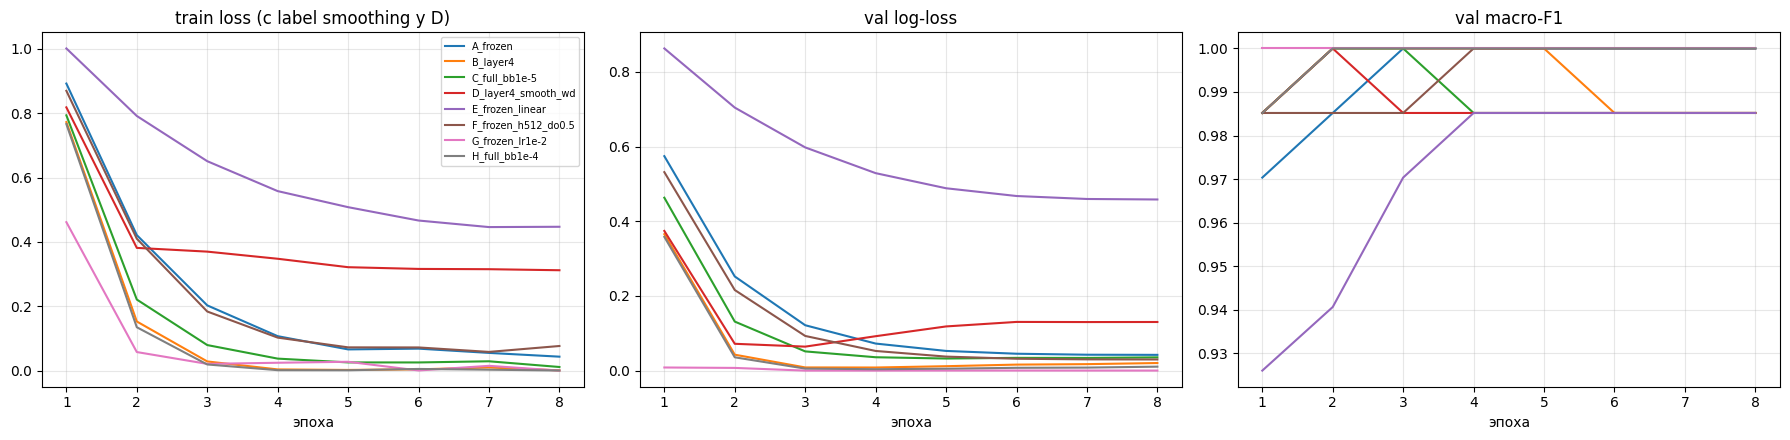

In [19]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for r in results:
    ep = [h["epoch"] for h in r["history"]]
    ax[0].plot(ep, [h["train_loss"] for h in r["history"]], label=r["name"])
    ax[1].plot(ep, [h["val_loss"] for h in r["history"]], label=r["name"])
    ax[2].plot(ep, [h["val_f1_macro"] for h in r["history"]], label=r["name"])
for a, t in zip(ax, ["train loss (с label smoothing у D)", "val log-loss", "val macro-F1"]):
    a.set_title(t); a.set_xlabel("эпоха"); a.grid(alpha=.3)
ax[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/curves.png", dpi=130); plt.show()

## 8. Ошибки выбранной модели

Конфигурация выбрана по validation macro-F1, затем log-loss на seed 42. Ниже код просмотра ошибок на test; фотографии не включены в сохранённые outputs.

In [21]:
best_r = max(results, key=lambda r: (r["best_val_f1"], -r["best_val_loss"]))
print("лучшая по val:", best_r["name"])
model = build_model(best_r["mode"], best_r["hidden"], best_r["dropout"]).to(dev)
model.load_state_dict(torch.load(f"{OUT_DIR}/{best_r['name']}.pt", map_location=dev))

test_items = splits[2]
_, ys, ps = evaluate(model, loaders[2], dev)
wrong = [i for i in range(len(ys)) if ys[i] != ps[i]]
print(f"ошибок: {len(wrong)} из {len(ys)}")

if wrong:
    show = wrong[:8]
    fig, ax = plt.subplots(2, 4, figsize=(14, 7.5))
    for a in ax.ravel():
        a.axis("off")
    for a, i in zip(ax.ravel(), show):
        p, y, w = test_items[i]
        a.imshow(Image.open(p).convert("RGB"))
        a.set_title(f"{wnid2name[w]}\nистина: {META_NAMES[ys[i]]}\nпредсказано: {META_NAMES[ps[i]]}", fontsize=9)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/errors.png", dpi=130); plt.show()


лучшая по val: G_frozen_lr1e-2
ошибок: 1 из 68


## 9. Схема эксперимента

Предобученные признаки сравниваются с fine-tuning на одинаковых разбиениях. Линейная и MLP-головы позволяют проверить пользу скрытого слоя; остальные конфигурации меняют регуляризацию и learning rate. В некоторых сравнениях меняется несколько параметров, поэтому их отдельный вклад не изолирован.

Validation используется для выбора checkpoint. Test-метрики всех конфигураций доступны в отчёте; дальнейший подбор по ним требует нового отложенного набора.

## 10. Результаты

Восемь конфигураций × четыре разбиения (`42, 1, 2, 3`), всего 32 обучения по 8 эпох.

На seed 42 выбор по validation macro-F1 и loss даёт **G_frozen_lr1e-2**: test accuracy **0,9853** (67/68), macro-F1 **0,9852**. По четырём разбиениям: accuracy **0,9890 ± 0,0074**, macro-F1 **0,9890 ± 0,0073**.

У A_frozen наибольшее среднее test accuracy: **0,9963 ± 0,0074**. Это результат сравнения, а не критерий выбора. На этой подвыборке fine-tuning не дал устойчивого преимущества перед замороженным backbone.

450 изображений, три метакласса, 68 примеров на одном test. Одна ошибка меняет accuracy на 1,47 п.п. Данные относятся к домену предобучения, а повторные разбиения пересекаются. Результат не переносится автоматически на новый домен.